# Train and evaluate ConvNeXt Tiny classifier

This notebook trains a ConvNeXt Tiny model on annotated beach-cell matrices. It uses split metadata from `Data/Preprocessed`, loads five channels per cell from `Data/Raw/Annotated_data`, and evaluates the test set with per-class precision, recall, and F1 score.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "Notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

source_path = PROJECT_ROOT / "Source"
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from Source.beach_dataset import (
    BeachCellDataset,
    FEATURE_SUFFIXES,
    class_weights,
    compute_channel_stats,
    find_missing_files,
    make_class_mapping,
    read_class_name_mapping,
    read_split_csv,
    summarize_nonfinite_values,
)
from Source.models import build_convnext_tiny
from Source.training import classification_metrics, fit_model, get_device, predict

/Users/piotr/Praca/Nauka/publikacje/Beach_classification/Beach_classification_software/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
ANNOTATED_ROOT = PROJECT_ROOT / "Data" / "Raw" / "Annotated_data"
CLASS_MAPPING_PATH = PROJECT_ROOT / "Data" / "Raw" / "Classes.xlsx"
PREPROCESSED_DIR = PROJECT_ROOT / "Data" / "Preprocessed"
OUTPUT_DIR = PROJECT_ROOT / "Results" / "convnext_tiny"

TRAIN_SPLIT = PREPROCESSED_DIR / "train_split.csv"
VALIDATION_SPLIT = PREPROCESSED_DIR / "validation_split.csv"
TEST_SPLIT = PREPROCESSED_DIR / "test_split.csv"

IMAGE_SIZE = 64
BATCH_SIZE = 32
NUM_WORKERS = 0
EPOCHS = 50
EARLY_STOPPING_PATIENCE = 5
EARLY_STOPPING_MIN_DELTA = 1e-4
USE_SPATIAL_AUGMENTATION = True
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
USE_PRETRAINED_IMAGENET_WEIGHTS = True
RANDOM_SEED = 42

torch.manual_seed(RANDOM_SEED)

print(f"Project root:    {PROJECT_ROOT}")
print(f"Annotated data:  {ANNOTATED_ROOT}")
print(f"Class mapping:   {CLASS_MAPPING_PATH}")
print(f"Output dir:      {OUTPUT_DIR}")
print(f"Feature order:   {FEATURE_SUFFIXES}")

Project root:    /Users/piotr/Praca/Nauka/publikacje/Beach_classification/Beach_classification_software
Annotated data:  /Users/piotr/Praca/Nauka/publikacje/Beach_classification/Beach_classification_software/Data/Raw/Annotated_data
Class mapping:   /Users/piotr/Praca/Nauka/publikacje/Beach_classification/Beach_classification_software/Data/Raw/Classes.xlsx
Output dir:      /Users/piotr/Praca/Nauka/publikacje/Beach_classification/Beach_classification_software/Results/convnext_tiny
Feature order:   ('r', 'g', 'b', 's', 'd')


In [3]:
train_df = read_split_csv(TRAIN_SPLIT)
validation_df = read_split_csv(VALIDATION_SPLIT)
test_df = read_split_csv(TEST_SPLIT)

class_to_idx = make_class_mapping(train_df, validation_df, test_df)
class_name_by_code = read_class_name_mapping(CLASS_MAPPING_PATH, class_to_idx.keys())
idx_to_class_code = {idx: label for label, idx in class_to_idx.items()}
idx_to_class_name = {
    idx: f"{code}: {class_name_by_code.get(code, f'class_{code}')}"
    for idx, code in idx_to_class_code.items()
}

class_table = pd.DataFrame(
    [
        {"encoded_class": code, "model_index": idx, "class_name": class_name_by_code.get(code, f"class_{code}")}
        for code, idx in class_to_idx.items()
    ]
).sort_values("model_index")

if all(name == f"class_{code}" for code, name in class_name_by_code.items()):
    print(
        "No class-name mapping was detected in Classes.xlsx; "
        "using fallback labels class_0, class_1, ..."
    )

print(f"Train rows:      {len(train_df):,}")
print(f"Validation rows: {len(validation_df):,}")
print(f"Test rows:       {len(test_df):,}")
display(class_table)

Train rows:      3,456
Validation rows: 741
Test rows:       741


,encoded_class,model_index,class_name
0,0,0,Snow
1,1,1,Dry sediment
2,2,2,Wet sediment
3,3,3,Water
4,4,4,Bedrock
5,5,5,Boulder
6,6,6,Driftwood
7,7,7,Algae
8,8,8,Ice
9,9,9,Anthropogenic


In [4]:
all_splits_df = pd.concat([train_df, validation_df, test_df], ignore_index=True)
missing_files = find_missing_files(all_splits_df, ANNOTATED_ROOT)

if not missing_files.empty:
    display(missing_files.head(50))
    raise FileNotFoundError(
        f"Missing {len(missing_files):,} expected matrix files. "
        "Run the copy_annotated_data notebook first or inspect the missing files above."
    )

print("All expected matrix files are present.")

All expected matrix files are present.


In [5]:
nonfinite_values = summarize_nonfinite_values(all_splits_df, ANNOTATED_ROOT)
if nonfinite_values.empty:
    print("No NaN or infinite matrix values found.")
else:
    display(
        nonfinite_values
        .groupby(["split" if "split" in nonfinite_values.columns else "date", "feature"], dropna=False)
        .agg(files=("path", "count"), nan_values=("nan_count", "sum"), inf_values=("inf_count", "sum"))
    )
    display(nonfinite_values.head(20))

channel_mean, channel_std = compute_channel_stats(train_df, ANNOTATED_ROOT)

stats_df = pd.DataFrame(
    {
        "feature": FEATURE_SUFFIXES,
        "mean": channel_mean,
        "std": channel_std,
    }
)
stats_df

files  nan_values  inf_values
split      feature                               
test       d            8         460           0
           s            8         446           0
train      d           22         812           0
           s           22         792           0
validation d            4          80           0
           s            4          80           0

,date,cell_id,class,feature,nan_count,inf_count,path,split
0,20240806,1100358,3,s,39,0,/Users/piotr/Praca/Nauka/publikacje/Beach_clas...,train
1,20240806,1100358,3,d,39,0,/Users/piotr/Praca/Nauka/publikacje/Beach_clas...,train
2,20240806,1101887,3,s,39,0,/Users/piotr/Praca/Nauka/publikacje/Beach_clas...,train
3,20240806,1101887,3,d,39,0,/Users/piotr/Praca/Nauka/publikacje/Beach_clas...,train
4,20240806,1138585,4,s,20,0,/Users/piotr/Praca/Nauka/publikacje/Beach_clas...,train
5,20240806,1138585,4,d,20,0,/Users/piotr/Praca/Nauka/publikacje/Beach_clas...,train
6,20240806,1198151,6,s,20,0,/Users/piotr/Praca/Nauka/publikacje/Beach_clas...,train
7,20240806,1198151,6,d,20,0,/Users/piotr/Praca/Nauka/publikacje/Beach_clas...,train
8,20240806,1924873,4,s,20,0,/Users/piotr/Praca/Nauka/publikacje/Beach_clas...,train
9,20240806,1924873,4,d,20,0,/Users/piotr/Praca/Nauka/publikacje/Beach_clas...,train


,feature,mean,std
0,r,118.646523,47.892353
1,g,122.686409,49.060795
2,b,126.339005,50.661888
3,s,17.237616,21.094479
4,d,0.394561,14.498202


In [6]:
train_dataset = BeachCellDataset(
    train_df,
    ANNOTATED_ROOT,
    class_to_idx,
    image_size=IMAGE_SIZE,
    mean=channel_mean,
    std=channel_std,
    augment=USE_SPATIAL_AUGMENTATION,
)
validation_dataset = BeachCellDataset(
    validation_df,
    ANNOTATED_ROOT,
    class_to_idx,
    image_size=IMAGE_SIZE,
    mean=channel_mean,
    std=channel_std,
)
test_dataset = BeachCellDataset(
    test_df,
    ANNOTATED_ROOT,
    class_to_idx,
    image_size=IMAGE_SIZE,
    mean=channel_mean,
    std=channel_std,
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
)
validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
)

x_batch, y_batch = next(iter(train_loader))
print(f"Input batch shape: {tuple(x_batch.shape)}")
print(f"Label batch shape: {tuple(y_batch.shape)}")

Input batch shape: (32, 5, 64, 64)
Label batch shape: (32,)


In [7]:
device = get_device()
model = build_convnext_tiny(
    num_classes=len(class_to_idx),
    in_channels=len(FEATURE_SUFFIXES),
    pretrained=USE_PRETRAINED_IMAGENET_WEIGHTS,
).to(device)

weights = class_weights(train_df, class_to_idx).to(device)
criterion = nn.CrossEntropyLoss(weight=weights)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

print(f"Device: {device}")
print(model.classifier)

Device: mps
Sequential(
  (0): LayerNorm2d((768,), eps=1e-06, elementwise_affine=True, bias=True)
  (1): Flatten(start_dim=1, end_dim=-1)
  (2): Linear(in_features=768, out_features=10, bias=True)
)


In [8]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
checkpoint_path = OUTPUT_DIR / "convnext_tiny_best.pt"

history = fit_model(
    model,
    train_loader,
    validation_loader,
    criterion,
    optimizer,
    device,
    epochs=EPOCHS,
    checkpoint_path=checkpoint_path,
    early_stopping_patience=EARLY_STOPPING_PATIENCE,
    early_stopping_min_delta=EARLY_STOPPING_MIN_DELTA,
)

history_path = OUTPUT_DIR / "training_history.csv"
history.to_csv(history_path, index=False)
history

Epoch 001 | train loss=1.1546, acc=0.6322 | val loss=0.6022, acc=0.7922


Epoch 002 | train loss=0.5083, acc=0.8186 | val loss=0.4107, acc=0.8462


Epoch 003 | train loss=0.3251, acc=0.8834 | val loss=0.4232, acc=0.8731


Epoch 004 | train loss=0.2759, acc=0.9008 | val loss=0.3479, acc=0.8920


Epoch 005 | train loss=0.1821, acc=0.9340 | val loss=0.2912, acc=0.8988


...

Epoch 011 | train loss=0.0471, acc=0.9829 | val loss=0.2929, acc=0.9190


Epoch 012 | train loss=0.0917, acc=0.9661 | val loss=0.4240, acc=0.8853


Epoch 013 | train loss=0.0738, acc=0.9740 | val loss=0.3360, acc=0.9163


Epoch 014 | train loss=0.0810, acc=0.9742 | val loss=0.3154, acc=0.9055
Early stopping after epoch 014. Best validation loss was 0.2603 at epoch 009.


,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy,is_best_epoch
0,1,1.154634,0.632234,0.602198,0.792173,False
1,2,0.508329,0.818576,0.410710,0.846154,False
2,3,0.325094,0.883391,0.423156,0.873144,False
3,4,0.275911,0.900752,0.347856,0.892038,False
4,5,0.182149,0.934028,0.291157,0.898785,False
5,6,0.160774,0.940104,0.312715,0.905533,False
6,7,0.106605,0.960938,0.269733,0.914980,False
7,8,0.119598,0.955729,0.382633,0.878543,False
8,9,0.103484,0.970197,0.260257,0.925776,True
9,10,0.056484,0.975405,0.273531,0.900135,False


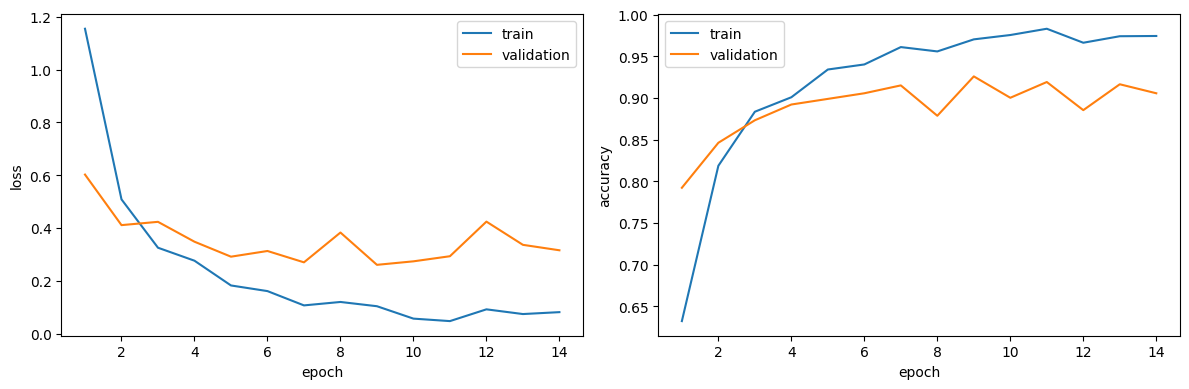

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history["epoch"], history["train_loss"], label="train")
axes[0].plot(history["epoch"], history["validation_loss"], label="validation")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("loss")
axes[0].legend()

axes[1].plot(history["epoch"], history["train_accuracy"], label="train")
axes[1].plot(history["epoch"], history["validation_accuracy"], label="validation")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("accuracy")
axes[1].legend()

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "training_history.png", dpi=150)
plt.show()

In [10]:
y_true, y_pred, y_probability = predict(model, test_loader, device)
report_df, confusion_df = classification_metrics(y_true, y_pred, idx_to_class_name)

report_path = OUTPUT_DIR / "test_classification_report.csv"
confusion_path = OUTPUT_DIR / "test_confusion_matrix.csv"

report_df.to_csv(report_path)
confusion_df.to_csv(confusion_path)

report_df

,precision,recall,f1-score,support
0: Snow,0.875000,0.933333,0.903226,15.000000
1: Dry sediment,0.937500,0.857143,0.895522,105.000000
2: Wet sediment,0.903226,0.943820,0.923077,89.000000
3: Water,0.962025,0.915663,0.938272,83.000000
4: Bedrock,0.885057,0.770000,0.823529,100.000000
5: Boulder,0.911111,0.891304,0.901099,92.000000
6: Driftwood,0.908046,0.987500,0.946108,80.000000
7: Algae,0.853846,0.982301,0.913580,113.000000
8: Ice,0.915254,0.931034,0.923077,58.000000
9: Anthropogenic,1.000000,0.666667,0.800000,6.000000


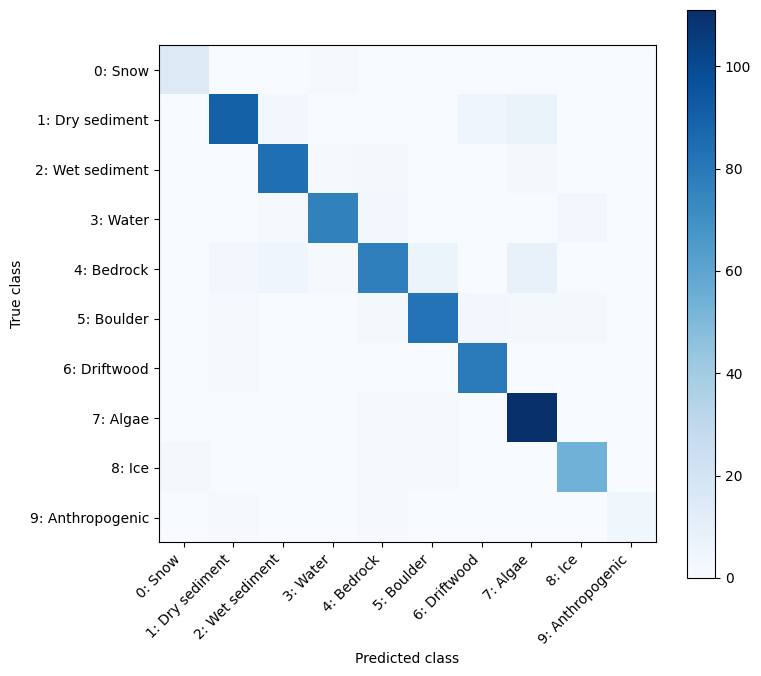

,0: Snow,1: Dry sediment,2: Wet sediment,3: Water,4: Bedrock,5: Boulder,6: Driftwood,7: Algae,8: Ice,9: Anthropogenic
0: Snow,14,0,0,1,0,0,0,0,0,0
1: Dry sediment,0,90,3,0,0,0,5,7,0,0
2: Wet sediment,0,0,84,1,2,0,0,2,0,0
3: Water,0,0,1,76,3,0,0,0,3,0
4: Bedrock,0,3,5,1,77,6,0,8,0,0
5: Boulder,0,1,0,0,2,82,3,2,2,0
6: Driftwood,0,1,0,0,0,0,79,0,0,0
7: Algae,0,0,0,0,1,1,0,111,0,0
8: Ice,2,0,0,0,1,1,0,0,54,0
9: Anthropogenic,0,1,0,0,1,0,0,0,0,4


In [11]:
fig, ax = plt.subplots(figsize=(8, 7))
image = ax.imshow(confusion_df.to_numpy(), cmap="Blues")
ax.set_xticks(range(len(confusion_df.columns)))
ax.set_yticks(range(len(confusion_df.index)))
ax.set_xticklabels(confusion_df.columns, rotation=45, ha="right")
ax.set_yticklabels(confusion_df.index)
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
fig.colorbar(image, ax=ax)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "test_confusion_matrix.png", dpi=150)
plt.show()

confusion_df

In [12]:
prediction_df = test_df.reset_index(drop=True).copy()
prediction_df["true_class_code"] = [idx_to_class_code[int(idx)] for idx in y_true]
prediction_df["predicted_class_code"] = [idx_to_class_code[int(idx)] for idx in y_pred]
prediction_df["true_class_name"] = [class_name_by_code[prediction_df.loc[i, "true_class_code"]] for i in range(len(prediction_df))]
prediction_df["predicted_class_name"] = [class_name_by_code[prediction_df.loc[i, "predicted_class_code"]] for i in range(len(prediction_df))]

for idx, class_code in idx_to_class_code.items():
    prediction_df[f"probability_class_{class_code}"] = y_probability[:, idx]

prediction_path = OUTPUT_DIR / "test_predictions.csv"
prediction_df.to_csv(prediction_path, index=False)

print(f"Saved checkpoint: {checkpoint_path}")
print(f"Saved history:    {history_path}")
print(f"Saved report:     {report_path}")
print(f"Saved confusion:  {confusion_path}")
print(f"Saved predictions:{prediction_path}")

prediction_df.head()

Saved checkpoint: /Users/piotr/Praca/Nauka/publikacje/Beach_classification/Beach_classification_software/Results/convnext_tiny/convnext_tiny_best.pt
Saved history:    /Users/piotr/Praca/Nauka/publikacje/Beach_classification/Beach_classification_software/Results/convnext_tiny/training_history.csv
Saved report:     /Users/piotr/Praca/Nauka/publikacje/Beach_classification/Beach_classification_software/Results/convnext_tiny/test_classification_report.csv
Saved confusion:  /Users/piotr/Praca/Nauka/publikacje/Beach_classification/Beach_classification_software/Results/convnext_tiny/test_confusion_matrix.csv
Saved predictions:/Users/piotr/Praca/Nauka/publikacje/Beach_classification/Beach_classification_software/Results/convnext_tiny/test_predictions.csv


,date,cell_id,class,split,true_class_code,predicted_class_code,true_class_name,predicted_class_name,probability_class_0,probability_class_1,probability_class_2,probability_class_3,probability_class_4,probability_class_5,probability_class_6,probability_class_7,probability_class_8,probability_class_9
0,20180722,1014749,3,test,3,3,Water,Water,0.000118,0.000051,0.000175,0.999093,0.000316,0.000034,0.000037,0.000022,0.000142,0.000013
1,20180722,1042265,4,test,4,4,Bedrock,Bedrock,0.000152,0.000256,0.001536,0.001121,0.973908,0.022007,0.000069,0.000154,0.000733,0.000064
2,20180722,1043796,4,test,4,5,Bedrock,Boulder,0.000330,0.000357,0.008530,0.000229,0.002722,0.985239,0.000516,0.000274,0.000496,0.001307
3,20180722,1051434,2,test,2,2,Wet sediment,Wet sediment,0.000053,0.001739,0.997606,0.000306,0.000071,0.000010,0.000068,0.000079,0.000015,0.000054
4,20180722,1054489,2,test,2,2,Wet sediment,Wet sediment,0.000101,0.001661,0.997482,0.000423,0.000089,0.000012,0.000054,0.000099,0.000022,0.000056
